### **Imports**

In [ ]:
#Download dataset from kaggle

#!/bin/bash
!kaggle datasets download marwandiab/medical-appointment-no-shows-dataset

Dataset URL: https://www.kaggle.com/datasets/marwandiab/medical-appointment-no-shows-dataset
License(s): unknown
100% 2.40M/2.40M [00:00<00:00, 20.7MB/s]



In [ ]:
#Unzip the dataset
!unzip medical-appointment-no-shows-dataset.zip

Archive:  medical-appointment-no-shows-dataset.zip
  inflating: noshowappointments.csv  


In [ ]:
#Import required python libraries to be used in this analysis
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression

### **Load Dataset**

In [ ]:
df = pd.read_csv('/content/noshowappointments.csv')

In [ ]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


### **Data Inspection**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [ ]:
df.shape

(110527, 14)

In [ ]:
#Inspect number of unique values in each column
df.nunique()

,0
PatientId,62299
AppointmentID,110527
Gender,2
ScheduledDay,103549
AppointmentDay,27
Age,104
Neighbourhood,81
Scholarship,2
Hipertension,2
Diabetes,2


In [ ]:
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [ ]:
#Check for any invalid records where age <0
df[df['Age'] < 0]

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
99832,4.659432e+14,5775010,F,2016-06-06T08:58:13Z,2016-06-06T00:00:00Z,-1,ROMÃO,0,0,0,0,0,0,No


In [ ]:
#Remove age <0
df = df[df['Age'] >= 0].copy()

In [ ]:
#check wghere age equals 0
(df['Age'] == 0).sum()

np.int64(3539)

In [ ]:
#Age == 0 could be wrong or children below 1 year, check that none of Age==0 records do not any other Adult-like attribute i.e. Alcoholism
print(f"Number of records where Age is Zero and Alcoholism is true: {df[(df['Age'] == 0) & (df['Alcoholism'] == 1)].sum().sum():.0f}")

Number of records where Age is Zero and Alcoholism is true: 0


In [ ]:
#Inspect dataset head/top records
df['Age'].value_counts().sort_index().head(20)

,count
Age,
0,3539
1,2273
2,1618
3,1513
4,1299
5,1489
6,1521
7,1427
8,1424


In [ ]:
#Inspect dataset tail/bottom 20 records
df['Age'].value_counts().sort_index().tail(20)

,count
Age,
83,280
84,311
85,275
86,260
87,184
88,126
89,173
90,109
91,66


In [ ]:
df[df['Age'] > 100][['Age', 'Gender', 'No-show']]

,Age,Gender,No-show
58014,102,F,No
63912,115,F,Yes
63915,115,F,Yes
68127,115,F,Yes
76284,115,F,No
90372,102,F,No
97666,115,F,No


- The single record with an age of -1 was identified as an invalid observation and will be removed.
- Age values of 0 and values above 100 will be retained because the available data do not provide sufficient evidence to classify them as invalid.

In [ ]:
#Handcap distribution
df['Handcap'].value_counts().sort_index()

,count
Handcap,
0,108285
1,2042
2,183
3,13
4,3


`Handcap` contains values ranging from 0 to 4, with the majority of observations having a value of 0. The values above 0 will be retained during data cleaning and further examined during exploratory analysis.

In [ ]:
df.describe(include='object')

,Gender,ScheduledDay,AppointmentDay,Neighbourhood,No-show
count,110526,110526,110526,110526,110526
unique,2,103548,27,81,2
top,F,2016-05-06T07:09:54Z,2016-06-06T00:00:00Z,JARDIM CAMBURI,No
freq,71839,24,4691,7717,88207


In [ ]:
#Check binary columns (int64 with two unique values)
binary_cols = [
    'Scholarship',
    'Hipertension',
    'Diabetes',
    'Alcoholism',
    'SMS_received'
]

In [ ]:
df[binary_cols].apply(lambda col: col.value_counts().sort_index())

,Scholarship,Hipertension,Diabetes,Alcoholism,SMS_received
0,99665,88725,102583,107166,75044
1,10861,21801,7943,3360,35482


In [ ]:
df.groupby('No-show').size()

,0
No-show,
No,88207
Yes,22319


In [ ]:
#determine diagnosis percentage spread
#Get number of observations
n = len(df)

yes_count = len(df[df['No-show'] == 'Yes'])
no_count = len(df[df['No-show'] == 'No'])

print(f"Percentage of No cases: {(no_count/n) * 100:.2f}%")
print(f"Percentage of Yes cases: {(yes_count/n) * 100:.2f}%")

Percentage of No cases: 79.81%
Percentage of Yes cases: 20.19%


In [ ]:
df['Gender'].value_counts()

,count
Gender,
F,71839
M,38687


In [ ]:
df['Neighbourhood'].value_counts()

,count
Neighbourhood,
JARDIM CAMBURI,7717
MARIA ORTIZ,5805
RESISTÊNCIA,4431
JARDIM DA PENHA,3877
ITARARÉ,3514
...,...
ILHA DO BOI,35
ILHA DO FRADE,10
AEROPORTO,8


In [ ]:
df['ScheduledDay'].min(), df['ScheduledDay'].max()

('2015-11-10T07:13:56Z', '2016-06-08T20:07:23Z')

In [ ]:
df['AppointmentDay'].min(), df['AppointmentDay'].max()

('2016-04-29T00:00:00Z', '2016-06-08T00:00:00Z')

In [ ]:
df.isna().sum()

,0
PatientId,0
AppointmentID,0
Gender,0
ScheduledDay,0
AppointmentDay,0
Age,0
Neighbourhood,0
Scholarship,0
Hipertension,0
Diabetes,0


In [ ]:
# Check how many duplicate records exists in the dataset
df.duplicated().sum()

np.int64(0)

In [ ]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [ ]:
# verification after removing one record with age = -1, droping appointmentID and patientID features
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Minimum age:", df['Age'].min())

Shape: (110526, 14)
Missing values: 0
Duplicate rows: 0
Minimum age: 0


## **After cleaning Notes**

#### **1. Initial Dataset Inspection**
- Dataset: Brazilian Medical Appointment No-Show dataset.
- Initial dataset size: 110,527 records × 14 variables.
- No missing values identified.
- No exact duplicate records identified.
- AppointmentID: 110,527 unique values.
- PatientId: 62,299 unique values, indicating that some patients have multiple appointments.
- Gender: 2 unique values (F, M).
- Neighbourhood: 81 unique categories.
- No-show: 2 classes (No, Yes).
#### **2. Target Variable Inspection**
- No-show = No - 88,208 (79.81%).
- No-show = Yes - 22,319 (20.19%).
- Class imbalance identified.
- Class imbalance will be considered during model development through comparison of baseline, SMOTE and RUS approaches.
#### **3. Numerical Variable Inspection**
 - Age: range initially identified as -1 to 115.
 - Age = -1: 1 record identified as invalid.
 - Age = 0: 3,539 records; retained because zero could represent a valid age and cannot be conclusively classified as erroneous.
 - Ages above 100 were inspected:
    - Age 102: 2 records
    - Age 115: 5 records
- Ages above 100 retained because there was insufficient evidence to classify them as invalid.
- Handcap: values range from 0–4; retained for further analysis.
#### **4. Binary Variable Inspection**
The following variables contain only expected binary values: 0 (No) and 1 (Yes):

 - Scholarship
 - Hipertension
 - Diabetes
 - Alcoholism
 - SMS_received

No invalid values identified in these variables.

####**5. Categorical Variable Inspection**
 - Gender: only F and M identified.
 - Neighbourhood: 81 categories identified, including some low-frequency categories.
 - No-show: only Yes and No identified.
 - No obvious invalid categorical values identified.
####**6. Date Variable Inspection**
 - ScheduledDay: 2015-11-10 to 2016-06-08.
 - AppointmentDay: 2016-04-29 to 2016-06-08.
 - Both variables are currently stored as strings.
 - Date variables will be converted to datetime during preprocessing.
 - The difference between scheduled and appointment dates will be considered during feature engineering.
####**7. Identifier Inspection**
 - PatientId is not unique because patients may have multiple appointments.
 - AppointmentID is unique for every record.
 - Both identifiers will be excluded from predictive modelling because they are identifiers rather than meaningful predictive features.
####**8. Cleaning Performed**
 - Removed the single record with Age = -1.
 - No missing values required treatment.
 - No duplicate records required removal.
 - No other records were removed based on the initial inspection.
####**9. Post-Cleaning Verification**
 - Final dataset size: 110,526 records × 14 variables.
 - Missing values: 0.
 - Duplicate rows: 0.
 - Minimum age: 0.
Dataset passed the initial cleaning verification.

###**EDA**

In [ ]:
#Drop AppointmentID and patientID, as they represent a unique ID for each appointment and patient respectively and have no effect in missed appointments
df = df.drop(columns=['AppointmentID', 'PatientId'])

#####**Age**

In [ ]:
#Age distribution
df['Age'].describe()

,Age
count,110526.000000
mean,37.089219
std,23.110026
min,0.000000
25%,18.000000
50%,37.000000
75%,55.000000
max,115.000000


In [ ]:
df.groupby('No-show')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
No-show,,,,,,,,
No,88207.0,37.790504,23.338645,0.0,18.0,38.0,56.0,115.0
Yes,22319.0,34.317667,21.965941,0.0,16.0,33.0,51.0,115.0


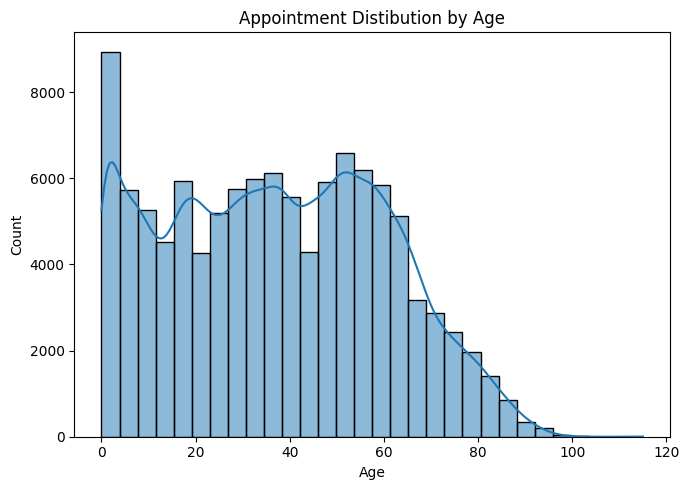

In [ ]:
# Visualising the distribution of Age
plt.figure(figsize=(7, 5))

sns.histplot(data=df['Age'], bins=30, kde=True)
plt.title('Appointment Distibution by Age')

plt.tight_layout()
plt.show()



- Age ranged from 0–115 years, with a mean of 37.09 and median of 37.
- The histogram shows that appointments are concentrated among younger and middle-aged patients, with frequencies generally decreasing at older ages and a relatively small number of observations among patients above 80 years.
- No-show patients were younger on average (34.32 years) than patients who attended (37.79 years).
- This observed difference suggests that age may be relevant to predicting appointment attendance and will be retained as a modelling feature.

#####**Gender**

In [ ]:
pd.crosstab(df['Gender'], df['No-show'])

No-show,No,Yes
Gender,,
F,57245,14594
M,30962,7725


In [ ]:
pd.crosstab(df['Gender'], df['No-show'], normalize='index').mul(100).round(2)

No-show,No,Yes
Gender,,
F,79.69,20.31
M,80.03,19.97


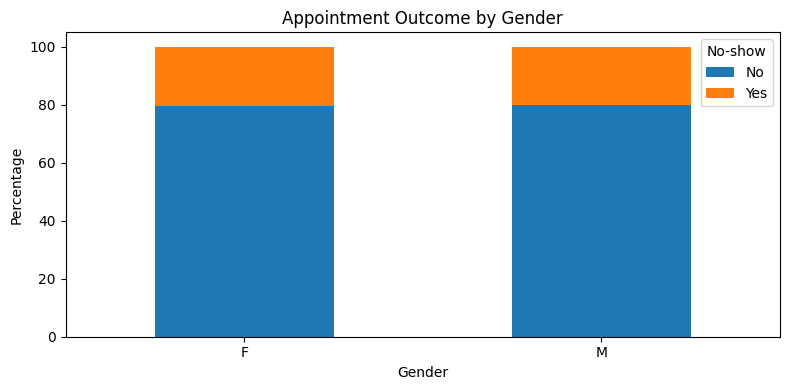

In [ ]:
gender_noshow = pd.crosstab(df['Gender'],df['No-show'],normalize='index') * 100

gender_noshow.plot(kind='bar', stacked=True, figsize=(8, 4))

plt.xlabel('Gender')
plt.ylabel('Percentage')
plt.title('Appointment Outcome by Gender')
plt.xticks(rotation=0)
plt.legend(title='No-show')

plt.tight_layout()
plt.show()

- The dataset contains 71,840 female (F) and 38,686 male (M) appointment records, indicating a higher representation of female appointments.
- Among female appointments, 20.31% were no-shows, compared with 19.97% among male appointments.
- The 100% stacked bar chart shows very similar appointment-outcome proportions across gender, with approximately 80% attended and 20% no-show for both groups.
- The observed difference in no-show proportions between females and males is small (0.34 percentage points).
 - Gender will therefore be retained as a candidate modelling feature, allowing the machine learning models to determine whether it contributes useful predictive information.
- The observed differences represent associations within the dataset and do not establish a causal relationship.

#####**Neighbourhood**

In [ ]:
df['Neighbourhood'].value_counts()

,count
Neighbourhood,
JARDIM CAMBURI,7717
MARIA ORTIZ,5805
RESISTÊNCIA,4431
JARDIM DA PENHA,3877
ITARARÉ,3514
...,...
ILHA DO BOI,35
ILHA DO FRADE,10
AEROPORTO,8


- The dataset contains 81 neighbourhood categories, with substantial variation in the number of appointment records across categories.
- Several neighbourhoods have very low observation counts, including categories represented by only a small number of appointments.
- Neighbourhood represents location-specific categories from the Brazilian source dataset.
- Individual neighbourhood-level patterns will not be interpreted as representative of South African geographical or healthcare conditions.
- **Due to the location-specific nature of the variable and its limited contextual transferability to the South African healthcare setting, Neighbourhood will be excluded from predictive modelling**.
- The variable will therefore be retained in the original dataset description but excluded from the modelling feature set.

###**Binary columns**

In [ ]:
binary_cols = [
    'Scholarship',
    'Hipertension',
    'Diabetes',
    'Alcoholism',
    'Handcap',
    'SMS_received'
]

In [ ]:
binary_summary = []

for col in binary_cols:
    rates = df.groupby(col)['No-show'].apply(lambda x: (x == 'Yes').mean() * 100)

    binary_summary.append({
        'Characteristic': col,
        'Category 0 (No-show Rate)': rates.get(0),
        'Category 1 (No-show Rate)': rates.get(1),
        'Difference (percentage points)': rates.get(1) - rates.get(0)
    })

In [ ]:
pd.DataFrame(binary_summary).round(2)

,Characteristic,Category 0 (No-show Rate),Category 1 (No-show Rate),Difference (percentage points)
0,Scholarship,19.81,23.74,3.93
1,Hipertension,20.90,17.30,-3.60
2,Diabetes,20.36,18.00,-2.36
3,Alcoholism,20.19,20.15,-0.05
4,Handcap,20.24,17.92,-2.31
5,SMS_received,16.70,27.57,10.87


 - Scholarship: Appointments involving patients with Scholarship = 1 had a no-show rate of 23.74%, compared with 19.81% for Scholarship = 0, a difference of 3.93 percentage points.
 - Hypertension: Appointments with Hypertension = 1 had a no-show rate of 17.30%, compared with 20.90% for `Hypertension = 0**, a difference of -3.60 percentage points.
 - Diabetes: Appointments with Diabetes = 1 had a no-show rate of 18.00%, compared with 20.36% for `Diabetes = 0**, a difference of -2.36 percentage points.
 - Alcoholism: No-show rates were almost identical for Alcoholism = 1 (20.15%) and Alcoholism = 0 (20.19%), with a difference of -0.05 percentage points.
 - SMS received: Appointments where an SMS was received had a no-show rate of 27.57%, compared with 16.70% where an SMS was not received, representing a difference of 10.87 percentage points.

Overall, the binary variables showed varying levels of observed association with the no-show outcome, with the largest difference observed for SMS receipt. These findings are descriptive and do not establish causal relationships.

#####**Scheduled and Appointment Day**

In [ ]:
#Convert to datetime variable type
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

In [ ]:
#Calculate number of waiting days
df['WaitingDays'] = (df['AppointmentDay'].dt.normalize() - df['ScheduledDay'].dt.normalize()).dt.days

df['WaitingDays'].describe()

,WaitingDays
count,110526.000000
mean,10.183794
std,15.255034
min,-6.000000
25%,0.000000
50%,4.000000
75%,15.000000
max,179.000000


In [ ]:
#Number of appointment with waiting days below zero
(df['WaitingDays'] < 0).sum()

np.int64(5)

In [ ]:
#Investiagte why we have 5 rows where the waiting days are negative/below zero.

#1. Get the actual rows where waiting days is less than zero
df.loc[df['WaitingDays'] < 0, ['ScheduledDay', 'AppointmentDay', 'WaitingDays', 'No-show']]

,ScheduledDay,AppointmentDay,WaitingDays,No-show
27033,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,-1,Yes
55226,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,-1,Yes
64175,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,-1,Yes
71533,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,-6,Yes
72362,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,-1,Yes


In [ ]:
#Filter out observations with waitingDays <0
df = df[df['WaitingDays'] >= 0].copy()

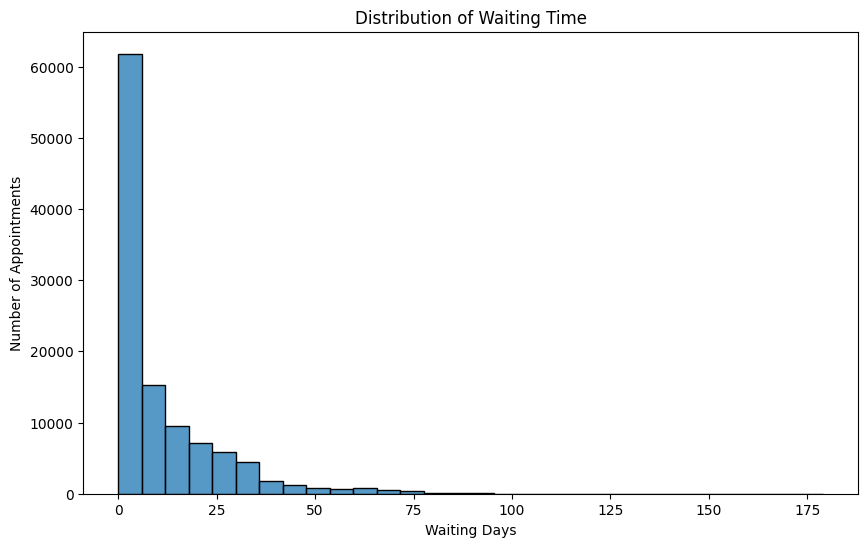

In [ ]:
#2. Distribution of waiting time
plt.figure(figsize=(10, 6))

sns.histplot(data=df['WaitingDays'], bins=30)

plt.xlabel('Waiting Days')
plt.ylabel('Number of Appointments')
plt.title('Distribution of Waiting Time')

plt.show()

In [ ]:
df['WaitingDays'].value_counts().sort_index().head(10)

,count
WaitingDays,
0,38562
1,5213
2,6725
3,2737
4,5290
5,3277
6,4037
7,4906
8,2332


In [ ]:
waiting_bins = pd.cut(df['WaitingDays'],bins=[-np.inf, 0, 3, 7, 14, 30, 60, 90, np.inf],
    labels=[
        '≤ 0 days',
        '1–3 days',
        '4–7 days',
        '8–14 days',
        '15–30 days',
        '31–60 days',
        '61–90 days',
        '> 90 days'
    ]
)

In [ ]:
waiting_summary = (df.groupby(waiting_bins, observed=False)['No-show'].agg(Appointments='size', No_Show_Rate=lambda x: (x == 'Yes').mean() * 100).round(2))

waiting_summary

,Appointments,No_Show_Rate
WaitingDays,,
≤ 0 days,38562,4.65
1–3 days,14675,22.89
4–7 days,17510,25.20
8–14 days,12025,30.47
15–30 days,17371,32.59
31–60 days,8283,34.15
61–90 days,1878,28.75
> 90 days,217,25.81


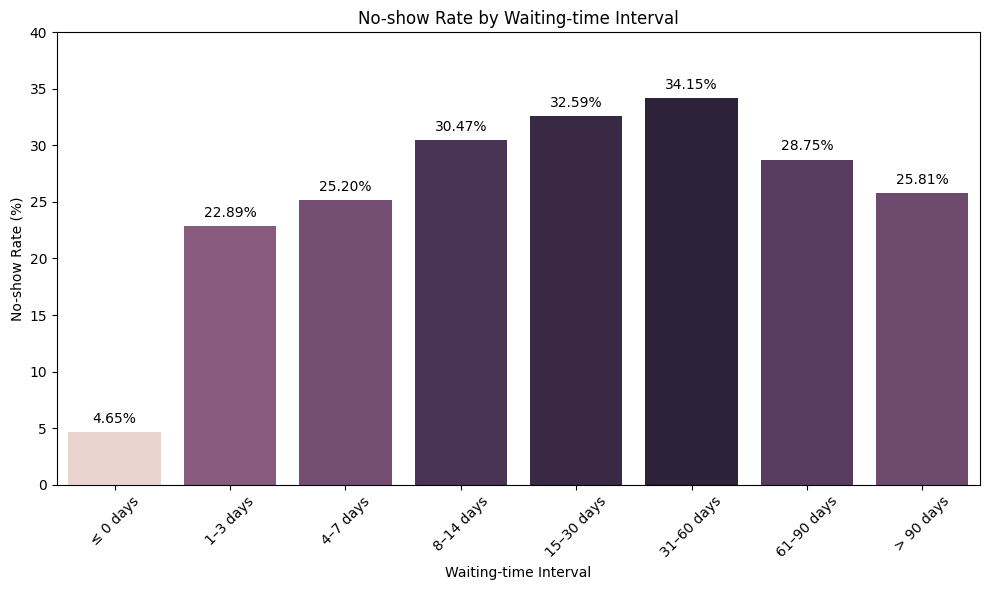

In [ ]:
#No-show Rate by Waiting-time Interval
plt.figure(figsize=(10, 6))

sns.barplot(waiting_summary,
            y=waiting_summary["No_Show_Rate"],
            x=waiting_summary.index.astype(str),
            hue=waiting_summary["No_Show_Rate"], legend=False)

plt.xlabel("Waiting-time Interval")
plt.ylabel("No-show Rate (%)")
plt.title("No-show Rate by Waiting-time Interval")
plt.xticks(rotation=45)
plt.ylim(0, 40)

# Add percentage labels
for i, value in enumerate(waiting_summary["No_Show_Rate"]):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
#No-show rate for appointments with waiting days <=0
df.groupby('WaitingDays')['No-show'].agg(Appointments='size', No_Show_Rate=lambda x: (x == 'Yes').mean() * 100).head(3)

,Appointments,No_Show_Rate
WaitingDays,,
0,38562,4.647062
1,5213,21.350470
2,6725,23.821561


In [ ]:
df['WaitingDays'].isna().sum()

np.int64(0)

In [ ]:
df['WaitingDays'].describe()

,WaitingDays
count,110521.000000
mean,10.184345
std,15.255153
min,0.000000
25%,0.000000
50%,4.000000
75%,15.000000
max,179.000000


- Waiting time ranged from -6 to 179 days, with a mean of 10.18 days and median of 4 days before treatment of the inconsistent records.
- The histogram showed a strong right-skewed distribution, with a large concentration of same-day appointments and progressively fewer appointments at longer waiting times.
- There were 38,562 appointments with a waiting time of 0 days, with a no-show rate of 4.65%.
- The no-show rate increased from 22.89% for 1–3 days to 34.15% for 31–60 days, before declining among the smaller groups with longer waiting periods.
- Five records had negative waiting times, comprising four records at -1 day and one at -6 days. All five were recorded as no-shows and were identified as inconsistent date relationships.
- The five negative waiting-time values will be treated as invalid values for the derived WaitingDays feature, while the underlying appointment records will be retained.
- Waiting time will be retained as a candidate modelling feature.
The observed relationships are descriptive and do not establish a causal relationship.

In [ ]:
#Impute appointment day of the week for the appointmentDay
df['AppointmentDayOfWeek'] = df['AppointmentDay'].dt.day_name()

In [ ]:
df['AppointmentDayOfWeek'].value_counts()

,count
AppointmentDayOfWeek,
Wednesday,25866
Tuesday,25638
Monday,22713
Friday,19019
Thursday,17246
Saturday,39


In [ ]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

day_summary = (
    df.groupby('AppointmentDayOfWeek')['No-show']
      .agg(Appointments='size', No_Show_Rate=lambda x: (x == 'Yes').mean() * 100).reindex(day_order).round(2)
)

In [ ]:
day_summary

,Appointments,No_Show_Rate
AppointmentDayOfWeek,,
Monday,22713.0,20.64
Tuesday,25638.0,20.09
Wednesday,25866.0,19.69
Thursday,17246.0,19.35
Friday,19019.0,21.23
Saturday,39.0,23.08
Sunday,NaN,NaN


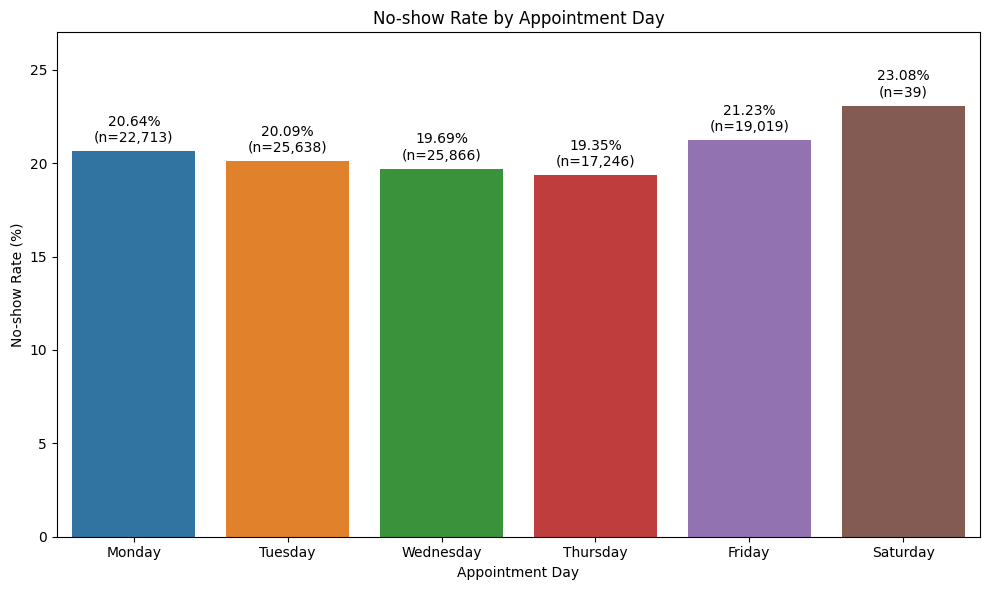

In [ ]:
plt.figure(figsize=(10, 6))

day_summary = day_summary[day_summary['Appointments'].notna()]
sns.barplot(data=day_summary, y='No_Show_Rate', x='AppointmentDayOfWeek', hue='AppointmentDayOfWeek')

plt.xlabel('Appointment Day')
plt.ylabel('No-show Rate (%)')
plt.title('No-show Rate by Appointment Day')

# Add percentage + sample size
for i, row in day_summary.reset_index().iterrows():
    plt.text(i, row["No_Show_Rate"] + 0.5, f'{row["No_Show_Rate"]:.2f}%\n(n={int(row["Appointments"]):,})', ha="center")

plt.ylim(0, 27)
plt.tight_layout()
plt.show()

- Appointments were predominantly scheduled on weekdays, with Wednesday having the highest number of appointments (25,867), followed by Tuesday (25,640) and Monday (22,714).
- The observed no-show rates across Monday to Friday were relatively similar, ranging from 19.35% on Thursday to 21.23% on Friday.
- Saturday had the highest observed no-show rate at 23.08%, but this was based on only 39 appointments and should therefore be interpreted cautiously.
- No appointments were recorded on Sunday in the dataset.
- Overall, the weekday no-show rates show relatively limited variation, although some differences are observed across appointment days.
- AppointmentDayOfWeek will be retained as a candidate modelling feature to allow the classification models to determine whether appointment day contributes predictive information.

The observed differences represent associations within the dataset and do not establish causal relationships.

In [ ]:
#Get scheduled day's hour
df['ScheduledHour'] = df['ScheduledDay'].dt.hour

In [ ]:
df['ScheduledHour'].value_counts().sort_index()

,count
ScheduledHour,
6,1577
7,19213
8,15348
9,12823
10,11055
11,8462
12,5422
13,9034
14,9126


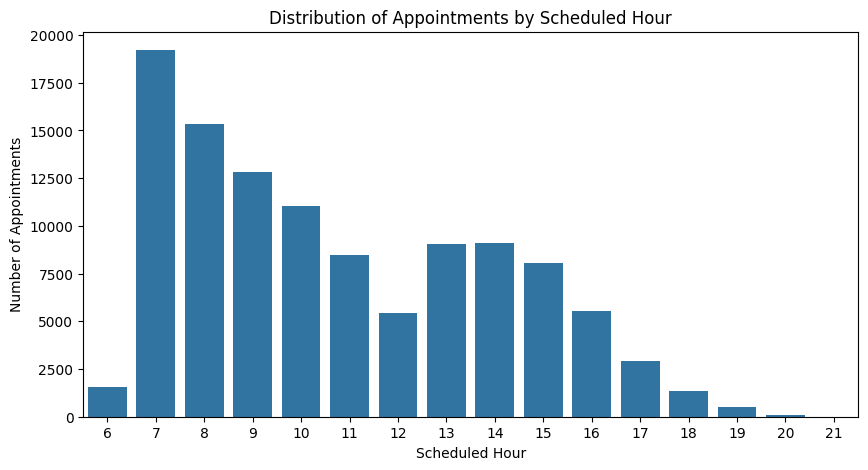

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df['ScheduledHour'].value_counts().sort_index())

plt.xlabel('Scheduled Hour')
plt.ylabel('Number of Appointments')
plt.title('Distribution of Appointments by Scheduled Hour')

plt.show()

In [ ]:
hour_summary = df.groupby('ScheduledHour')['No-show'].agg(
    Appointments='size',
    No_Show_Rate=lambda x: (x == 'Yes').mean() * 100
).round(2)

In [ ]:
hour_summary

,Appointments,No_Show_Rate
ScheduledHour,,
6,1577,19.15
7,19213,15.15
8,15348,18.27
9,12823,19.70
10,11055,22.06
11,8462,22.78
12,5422,20.36
13,9034,20.91
14,9126,22.67


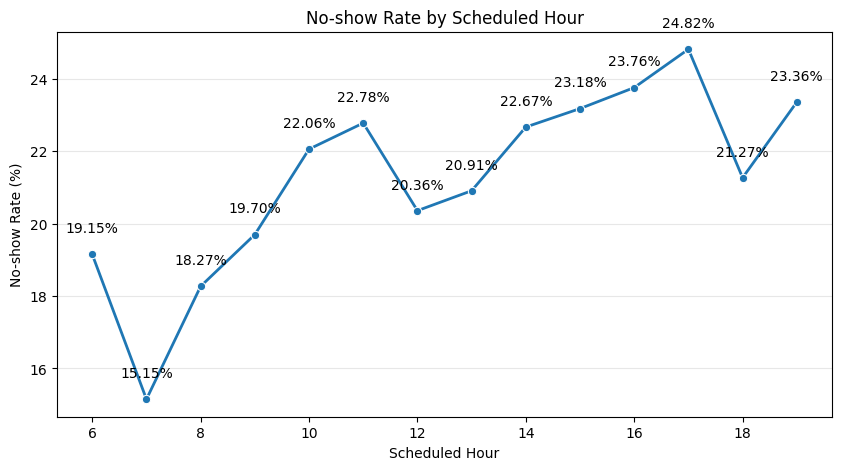

In [ ]:
plt.figure(figsize=(10, 5))

#Filter out any appointments below 300
hour_summary = hour_summary[hour_summary['Appointments'] >=300]

sns.lineplot(data=hour_summary, y='No_Show_Rate', x=hour_summary.index, legend=False, marker='o', linewidth=2)

# Add percentage labels
for x, y in zip(hour_summary.index,hour_summary["No_Show_Rate"]):
    plt.text(x, y + 0.6, f"{y:.2f}%", ha="center")

plt.grid(axis="y", alpha=0.3)

plt.xlabel('Scheduled Hour')
plt.ylabel('No-show Rate (%)')
plt.title('No-show Rate by Scheduled Hour')

plt.show()

 - Appointments were scheduled between 06:00 and 21:00, with the highest concentration occurring during the morning and early afternoon.
 - 07:00 had the largest number of appointments (19,213), followed by 08:00 (15,348) and 09:00 (12,823).
 - Appointment frequency generally decreased during the later hours, with only 488 appointments at 19:00, 100 at 20:00 and 3 at 21:00.
- The observed no-show rate was lowest at approximately 07:00 (15.2%) and generally increased across the later scheduled hours, reaching approximately 24.9% at 17:00.
 - The no-show rates at 20:00 and 21:00 were comparatively high, but these were based on only 100 and 3 appointments, respectively, and should therefore not be interpreted as reliable evidence of a higher no-show risk.
 - Overall, the analysis indicates an observed relationship between scheduled hour and no-show rate, with no-show rates generally higher during later appointment times, although the pattern becomes less reliable for sparsely represented hours.
 - ScheduledHour will be retained as a candidate modelling feature.

These observed differences represent associations within the dataset and do not establish a causal relationship.

#####**SMS Received**

In [ ]:
df.groupby('SMS_received')['WaitingDays'].describe()

,count,mean,std,min,25%,50%,75%,max
SMS_received,,,,,,,,
0,75039.0,6.007983,12.333825,0.0,0.0,0.0,6.0,179.0
1,35482.0,19.016713,16.978718,3.0,7.0,14.0,27.0,179.0


In [ ]:
df.groupby([waiting_bins, 'SMS_received'], observed=False)['No-show'].agg(
    Appointments='size',
    No_Show_Rate=lambda x: (x == 'Yes').mean() * 100
).round(2)

Appointments  No_Show_Rate
WaitingDays SMS_received                            
≤ 0 days    0                    38562          4.65
            1                        0           NaN
1–3 days    0                    13769         22.99
            1                      906         21.30
4–7 days    0                     6868         27.11
            1                    10642         23.97
8–14 days   0                     5021         33.76
            1                     7004         28.11
15–30 days  0                     6851         36.87
            1                    10520         29.80
31–60 days  0                     3224         38.37
            1                     5059         31.47
61–90 days  0                      666         34.98
            1                     1212         25.33
> 90 days   0                       78         24.36
            1                      139         26.62

In [ ]:
df.groupby("SMS_received")["WaitingDays"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
SMS_received,,,
0,75039,6.01,0.0
1,35482,19.02,14.0


- Overall, appointments where an SMS was received had a higher observed no-show rate (27.57%) than appointments where no SMS was received (16.70%).
- The SMS groups differed substantially in waiting time. Appointments with SMS_received = 0 had a median waiting time of 0 days, compared with 14 days for appointments with SMS_received = 1.
- When examined within waiting-time groups, the observed no-show rate was generally lower for appointments where an SMS was received across the 1–3, 4–7, 8–14, 15–30, 31–60 and 61–90 day groups.
- The higher overall no-show rate among SMS-received appointments therefore should not be interpreted as evidence that SMS reminders increase no-shows. The overall difference may reflect differences in the characteristics of appointments receiving SMS reminders, particularly waiting time.
- The results demonstrate the importance of considering relationships between variables rather than interpreting individual predictors in isolation.
- SMS_received will be retained as a candidate modelling feature, allowing the machine learning models to account for its relationship with other variables.

These findings are observational and do not establish a causal effect of SMS reminders on appointment attendance.

#####**Handicapped**

In [ ]:
df.groupby('Handcap')['No-show'].agg(
    Appointments='size',
    No_Show_Rate=lambda x: (x == 'Yes').mean() * 100
).round(2)

,Appointments,No_Show_Rate
Handcap,,
0,108282,20.23
1,2040,17.84
2,183,20.22
3,13,23.08
4,3,33.33


Handcap showed some variation in observed no-show rates across categories.

- Patients recorded as Handcap = 1 had a lower observed no-show rate (17.92%) than those recorded as Handcap = 0 (20.24%).
- However, categories 2, 3 and 4 contained substantially fewer observations, particularly categories 3 and 4, and their no-show rates should therefore be interpreted cautiously.

Handcap was retained as a candidate modelling feature, with the observed differences treated as associations rather than causal effects.

####**Correlation matrix**

In [ ]:
corr_df = df[
    [
        "Age",
        "Gender",
        "Scholarship",
        "Hipertension",
        "Diabetes",
        "Alcoholism",
        "Handcap",
        "SMS_received",
        "WaitingDays",
        "ScheduledHour"
    ]
].copy()

#Encode Gender
corr_df["Gender"] = corr_df["Gender"].map({"F":0, "M":1})

corr_matrix = corr_df.corr()

In [ ]:
corr_matrix.round(2)

,Age,Gender,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,WaitingDays,ScheduledHour
Age,1.00,-0.11,-0.09,0.50,0.29,0.10,0.08,0.01,0.03,0.01
Gender,-0.11,1.00,-0.11,-0.06,-0.03,0.11,0.02,-0.05,-0.03,-0.00
Scholarship,-0.09,-0.11,1.00,-0.02,-0.02,0.04,-0.01,0.00,-0.03,-0.02
Hipertension,0.50,-0.06,-0.02,1.00,0.43,0.09,0.08,-0.01,-0.02,-0.03
Diabetes,0.29,-0.03,-0.02,0.43,1.00,0.02,0.06,-0.01,-0.03,-0.01
Alcoholism,0.10,0.11,0.04,0.09,0.02,1.00,0.00,-0.03,-0.04,-0.00
Handcap,0.08,0.02,-0.01,0.08,0.06,0.00,1.00,-0.02,-0.02,0.00
SMS_received,0.01,-0.05,0.00,-0.01,-0.01,-0.03,-0.02,1.00,0.40,0.06
WaitingDays,0.03,-0.03,-0.03,-0.02,-0.03,-0.04,-0.02,0.40,1.00,0.08
ScheduledHour,0.01,-0.00,-0.02,-0.03,-0.01,-0.00,0.00,0.06,0.08,1.00


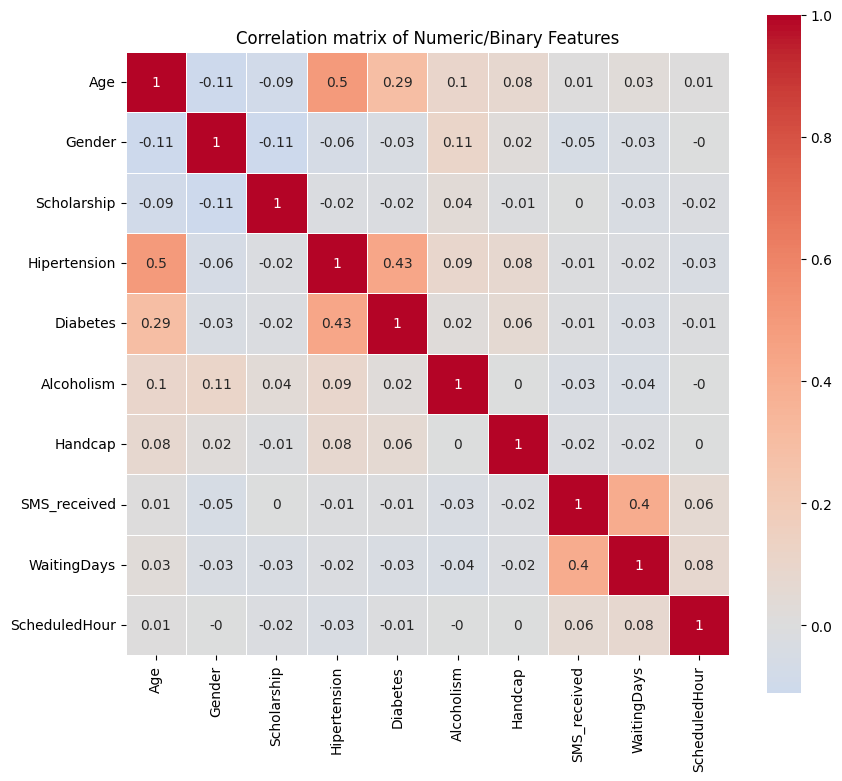

In [ ]:
plt.figure(figsize=(9, 8))

sns.heatmap(
    corr_matrix.round(2),
    annot=True,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('Correlation matrix of Numeric/Binary Features')

plt.tight_layout()
plt.show()

- Feature relationship analysis showed moderate associations between *Age* and *Hipertension* (0.50), *Hipertension* and *Diabetes* (0.43), and *WaitingDays* and *SMS_received* (0.40).
- The remaining numerical and binary feature relationships were generally weak. None of the observed relationships indicated sufficiently high redundancy to justify removing a candidate predictor.

*WaitingDays* and *SMS_received* were retained despite their moderate association because they represent distinct appointment-related characteristics.

### **Model Implemenation and Evaluation**

In [ ]:
#Create a model dataframe from current dataframe
model_df = df.copy()

# Keep only modelling variables
model_df = model_df[
    [
        'Age',
        'Gender',
        'Scholarship',
        'Hipertension',
        'Diabetes',
        'Alcoholism',
        'Handcap',
        'SMS_received',
        'WaitingDays',
        'AppointmentDayOfWeek',
        'ScheduledHour',
        'No-show'
    ]
].copy()

In [ ]:
model_df.head()

,Age,Gender,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,WaitingDays,AppointmentDayOfWeek,ScheduledHour,No-show
0,62,F,0,1,0,0,0,0,0,Friday,18,No
1,56,M,0,0,0,0,0,0,0,Friday,16,No
2,62,F,0,0,0,0,0,0,0,Friday,16,No
3,8,F,0,0,0,0,0,0,0,Friday,17,No
4,56,F,0,1,1,0,0,0,0,Friday,16,No


In [ ]:
model_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 110521 entries, 0 to 110526
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   Age                   110521 non-null  int64 
 1   Gender                110521 non-null  object
 2   Scholarship           110521 non-null  int64 
 3   Hipertension          110521 non-null  int64 
 4   Diabetes              110521 non-null  int64 
 5   Alcoholism            110521 non-null  int64 
 6   Handcap               110521 non-null  int64 
 7   SMS_received          110521 non-null  int64 
 8   WaitingDays           110521 non-null  int64 
 9   AppointmentDayOfWeek  110521 non-null  object
 10  ScheduledHour         110521 non-null  int32 
 11  No-show               110521 non-null  object
dtypes: int32(1), int64(8), object(3)
memory usage: 10.5+ MB


In [ ]:
#Drop the records where waiting days is NaN
model_df = model_df.dropna(subset=['WaitingDays']).copy()

In [ ]:
model_df.isnull().sum()

,0
Age,0
Gender,0
Scholarship,0
Hipertension,0
Diabetes,0
Alcoholism,0
Handcap,0
SMS_received,0
WaitingDays,0
AppointmentDayOfWeek,0


In [ ]:
#Encode the target variable
model_df['No-show'] = model_df['No-show'].map({'No': 0, 'Yes': 1})

In [ ]:
model_df['No-show'].value_counts()

,count
No-show,
0,88207
1,22314


In [ ]:
#Define features X and target variable y
X = model_df.drop(columns='No-show')
y = model_df['No-show']

In [ ]:
X.shape, y.shape

((110521, 11), (110521,))

In [ ]:
#Split dataset into 80/20 training and testing sets respectively
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

In [ ]:
print(f"Training set: {X_train.shape}, and Test set: {X_test.shape}")

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training set: (88416, 11), and Test set: (22105, 11)

Training target distribution:
No-show
0    79.81
1    20.19
Name: proportion, dtype: float64

Test target distribution:
No-show
0    79.81
1    20.19
Name: proportion, dtype: float64


In [ ]:
numeric_features = ['Age', 'WaitingDays', 'ScheduledHour']
categorical_features = ['Gender', 'AppointmentDayOfWeek']
binary_features = ['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received']

In [ ]:
from sklearn.compose import ColumnTransformer

#Use OneHotEncoder to encode for categorical features
#Use StandardScaler to scale/standardise numeric features.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [ ]:
#Baseline Model pipelines

lr_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

rf_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

xgb_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

In [ ]:
#SMOTE model pipelines

lr_smote = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', SMOTE(random_state=42)),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

rf_smote = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

xgb_smote = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', SMOTE(random_state=42)),
    ('model', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

In [ ]:
#Random Under-Sampling Model pipelines
lr_rus = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', RandomUnderSampler(random_state=42)),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

rf_rus = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', RandomUnderSampler(random_state=42)),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

xgb_rus = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', RandomUnderSampler(random_state=42)),
    ('model', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

In [ ]:
#Stratified k-fold cross-validation (k=5)
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
#Define metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

In [ ]:
#Evaluate Baseline models
from sklearn.model_selection import cross_validate

baseline_models = {
    'Logistic Regression': lr_baseline,
    'Random Forest': rf_baseline,
    'XGBoost': xgb_baseline
}

baseline_results = {}

for name, model in baseline_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    baseline_results[name] = {
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'AUC-ROC': scores['test_roc_auc'].mean()
    }

In [ ]:
baseline_results_df = pd.DataFrame(baseline_results).T.round(2)

baseline_results_df

,Accuracy,Precision,Recall,F1,AUC-ROC
Logistic Regression,0.79,0.32,0.02,0.03,0.66
Random Forest,0.77,0.37,0.21,0.27,0.70
XGBoost,0.80,0.45,0.06,0.10,0.73


Baseline cross-validation results indicated that the models achieved relatively high accuracy but comparatively low recall for the no-show class.

- Logistic Regression achieved an accuracy of 0.79 but a no-show recall of only 0.02, while XGBoost achieved the highest accuracy (0.80) and AUC-ROC (0.73) but a no-show recall of 0.06.
- Random Forest achieved the highest no-show recall (0.21) and F1-score (0.27) among the baseline models.

These results indicate that overall accuracy alone does not adequately reflect the models' ability to identify no-show appointments and support the evaluation of class-imbalance handling techniques.

In [ ]:
#SMOTE model evaluation
smote_models = {
    'Logistic Regression': lr_smote,
    'Random Forest': rf_smote,
    'XGBoost': xgb_smote
}

smote_results = {}

for name, model in smote_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    smote_results[name] = {
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'AUC-ROC': scores['test_roc_auc'].mean()
    }

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [ ]:
smote_results_df = pd.DataFrame(smote_results).T.round(2)

smote_results_df

,Accuracy,Precision,Recall,F1,AUC-ROC
Logistic Regression,0.66,0.32,0.57,0.41,0.67
Random Forest,0.74,0.34,0.33,0.33,0.70
XGBoost,0.79,0.43,0.17,0.24,0.73


Application of SMOTE substantially improved identification of the minority no-show class.

- Logistic Regression showed the largest improvement, with recall increasing from 0.02 to 0.57 and F1-score from 0.03 to 0.41, although accuracy decreased from 0.79 to 0.66.
- Random Forest also improved in recall and F1-score, while XGBoost showed a smaller improvement. AUC-ROC remained broadly unchanged for Random Forest and XGBoost, indicating that resampling primarily affected classification performance at the selected decision threshold rather than overall class discrimination.

These results demonstrate the trade-off between overall accuracy and the ability to identify no-show appointments.

In [ ]:
#RUS Eval
rus_models = {
    'Logistic Regression': lr_rus,
    'Random Forest': rf_rus,
    'XGBoost': xgb_rus
}

rus_results = {}

for name, model in rus_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    rus_results[name] = {
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'AUC-ROC': scores['test_roc_auc'].mean()
    }

In [ ]:
rus_results_df = pd.DataFrame(rus_results).T.round(2)

rus_results_df

,Accuracy,Precision,Recall,F1,AUC-ROC
Logistic Regression,0.66,0.32,0.57,0.41,0.67
Random Forest,0.61,0.30,0.69,0.42,0.70
XGBoost,0.61,0.31,0.78,0.44,0.73


Random Under-Sampling produced the strongest improvement in no-show recall for the tree-based models.

- Random Forest recall increased from 0.21 under the baseline condition to 0.69, while XGBoost recall increased from 0.06 to 0.78. Their corresponding F1-scores increased from 0.27 to 0.42 and from 0.10 to 0.44, respectively.
- However, both models experienced a substantial reduction in accuracy to 0.61 and a reduction in precision. Logistic Regression produced identical results under SMOTE and Random Under-Sampling, with recall of 0.57 and F1-score of 0.41.
- AUC-ROC remained unchanged within each model across the three class-imbalance conditions.

Overall, the results demonstrate a clear trade-off between identifying no-show appointments and maintaining overall classification accuracy.

#### **Hyperparam Tuning**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
#Logistic Regression Tuning
lr_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs']
}

lr_search = RandomizedSearchCV(
    estimator=lr_smote,
    param_distributions=lr_param_grid,
    n_iter=10,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lr_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['Age',
                                                                                'WaitingDays',
                                                                                'ScheduledHour']),
                                                                              ('cat',
                                                                               OneHotEncoder(handle_unknown='ignore',
                                                                                             sparse_output=False),
                                                                               ['Gender',
                                                                                'AppointmentDayOfWeek']),
                                                                              ('bin',
                                                                               'passthrough',
                                                                               ['Scholarship',
                                                                                'Hipertension',
                                                                                'Diabetes',
                                                                                'Alcoholism',
                                                                                'Handcap',
                                                                                'SMS_received'])])),
                                             ('resampler',
                                              SMOTE(random_state=42)),
                                             ('model',
                                              LogisticRegression(max_iter=1000,
                                                                 random_state=42))]),
                   n_jobs=-1,
                   param_distributions={'model__C': [0.01, 0.1, 1, 10, 100],
                                        'model__solver': ['liblinear',
                                                          'lbfgs']},
                   random_state=42, scoring='f1', verbose=1)

In [ ]:
print("Best parameters:", lr_search.best_params_)
print("Best CV F1:", round(lr_search.best_score_, 4))

Best parameters: {'model__solver': 'lbfgs', 'model__C': 0.01}
Best CV F1: 0.4085


In [ ]:
#RandomForest tuning
rf_param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

rf_search = RandomizedSearchCV(
    estimator=rf_rus,
    param_distributions=rf_param_grid,
    n_iter=10,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=1
)

rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['Age',
                                                                                'WaitingDays',
                                                                                'ScheduledHour']),
                                                                              ('cat',
                                                                               OneHotEncoder(handle_unknown='ignore',
                                                                                             sparse_output=False),
                                                                               ['Gender',
                                                                                'AppointmentDayOfWeek']),
                                                                              ('bin',
                                                                               'passthrough',
                                                                               ['Scholarshi...
                                             ('resampler',
                                              RandomUnderSampler(random_state=42)),
                                             ('model',
                                              RandomForestClassifier(n_jobs=-1,
                                                                     random_state=42))]),
                   n_jobs=2,
                   param_distributions={'model__max_depth': [None, 10, 20, 30],
                                        'model__max_features': ['sqrt', 'log2'],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [200, 300, 500]},
                   random_state=42, scoring='f1', verbose=1)

In [ ]:
print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 4))

Best parameters: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 30}
Best CV F1: 0.4463


In [ ]:
#XGBoost tuning
xgb_param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_rus,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['Age',
                                                                                'WaitingDays',
                                                                                'ScheduledHour']),
                                                                              ('cat',
                                                                               OneHotEncoder(handle_unknown='ignore',
                                                                                             sparse_output=False),
                                                                               ['Gender',
                                                                                'AppointmentDayOfWeek']),
                                                                              ('bin',
                                                                               'passthrough',
                                                                               ['Scholarshi...
                                                            monotone_constraints=None,
                                                            multi_strategy=None,
                                                            n_estimators=None,
                                                            n_jobs=-1,
                                                            num_parallel_tree=None, ...))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.8,
                                                                    1.0],
                                        'model__learning_rate': [0.01, 0.05,
                                                                 0.1],
                                        'model__max_depth': [3, 5, 7],
                                        'model__n_estimators': [200, 300, 500],
                                        'model__subsample': [0.7, 0.8, 1.0]},
                   random_state=42, scoring='f1', verbose=1)

In [ ]:
print("Best parameters:", xgb_search.best_params_)
print("Best CV F1:", round(xgb_search.best_score_, 4))

Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 500, 'model__max_depth': 7, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.7}
Best CV F1: 0.4486


Hyperparameters were tuned for each classification model using stratified 5-fold cross-validation on the training data.

1. For Logistic Regression, the regularisation strength (C) and solver were varied.
2. For Random Forest, the number of trees, maximum tree depth, minimum samples required for node splitting and leaf formation, and feature-selection strategy were varied.
3. For XGBoost, the number of boosting iterations, tree depth, learning rate, row subsampling and feature subsampling were varied.

These parameters were selected because they control model complexity, regularisation and learning behaviour. The F1-score for the no-show class was used as the primary metric for selecting the best configuration, given the study's focus on identifying appointments at risk of no-show.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score

#Evaluate Tuned models/best_estimators
tuned_models = {
    'Logistic Regression': lr_search.best_estimator_,
    'Random Forest': rf_search.best_estimator_,
    'XGBoost': xgb_search.best_estimator_
}

test_results = {}

for name, model in tuned_models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_prob)
    }

In [ ]:
test_results_df = pd.DataFrame(test_results).T.round(2)

test_results_df

,Accuracy,Precision,Recall,F1,AUC-ROC
Logistic Regression,0.66,0.31,0.57,0.40,0.66
Random Forest,0.60,0.31,0.79,0.44,0.72
XGBoost,0.59,0.31,0.82,0.45,0.73


- Evaluation on the independent test dataset showed that XGBoost achieved the strongest overall predictive performance, with an accuracy of 0.5884, precision of 0.3057, recall of 0.8174, F1-score of 0.4450 and AUC-ROC of 0.7284.
- Random Forest produced similar performance, with a recall of 0.7885, F1-score of 0.4412 and AUC-ROC of 0.7227.
- Logistic Regression achieved lower performance across the main predictive measures, with a recall of 0.5660 and F1-score of 0.4024.

The relatively low accuracy of the tree-based models reflects their greater identification of no-show appointments following Random Under-Sampling.

Given the study's focus on identifying appointments at risk of no-show, XGBoost was selected as the primary predictive model for the subsequent cost-sensitive decision analysis.

In [ ]:
#XGB probability distribution
xgb_final = xgb_search.best_estimator_

y_prob_xgb = xgb_final.predict_proba(X_test)[:, 1]

pd.Series(y_prob_xgb).describe()

,0
count,22105.000000
mean,0.446515
std,0.222735
min,0.059515
25%,0.175216
50%,0.519951
75%,0.634435
max,0.827153


- The selected XGBoost model produced a Brier score of 0.2135.
- The calibration plot showed that predicted no-show probabilities were generally higher than the corresponding observed no-show proportions, indicating overestimation of risk.

This suggests that the model provided useful discrimination but that its raw predicted probabilities should be interpreted cautiously when used as absolute risk estimates.

In [ ]:
#Predicted probabilities for the positive class (No-show = 1)
xgb_test_prob = xgb_final.predict_proba(X_test)[:, 1]

#Predicted classes
xgb_test_pred = (xgb_test_prob >= 0.5).astype(int)

#Create results dataframe
cost_df = X_test.copy()

cost_df["Actual_No_Show"] = y_test.values
cost_df["Predicted_No_Show"] = xgb_test_pred
cost_df["Predicted_No_Show_Probability"] = xgb_test_prob

In [ ]:
#Reset index for easier handling
cost_df = cost_df.reset_index(drop=True)

print(f"Cost framework dataset: {cost_df.shape}")

Cost framework dataset: (22105, 14)


In [ ]:
cost_df["Actual_No_Show"].value_counts()

,count
Actual_No_Show,
0,17642
1,4463


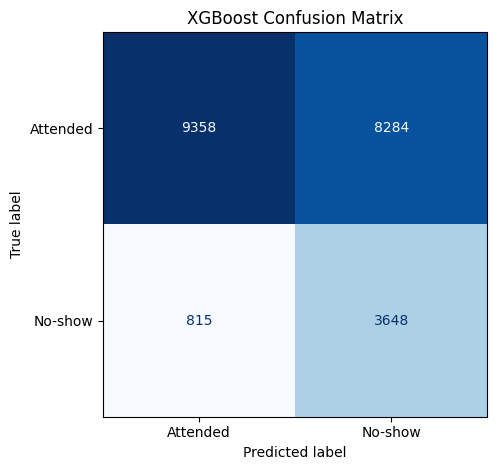

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Generate confusion matrix
cm = confusion_matrix(y_test, xgb_test_pred)

#Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Attended", "No-show"]
)

disp.plot(colorbar=False, cmap='Blues')
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix for the selected XGBoost model on the independent test dataset illustrates the below:
- The model correctly classified 9,358 appointments as attended and 3,648 appointments as no-shows. However, 8,284 appointments were incorrectly classified as no-shows, while 815 actual no-shows were incorrectly classified as attended.
- The relatively low number of false negatives compared with true positives indicates that the model identified a large proportion of actual no-shows, resulting in a recall of 81.74%.
- However, the high number of false positives resulted in a precision of 30.57%, indicating that many appointments classified as potential no-shows were in fact attended. This reflects the trade-off associated with prioritising identification of the minority no-show class.

This classification behaviour is relevant to the subsequent cost-sensitive decision framework, where intervention decisions are based on predicted no-show probabilities and the relative costs of intervention and missed appointments rather than on the classification threshold alone

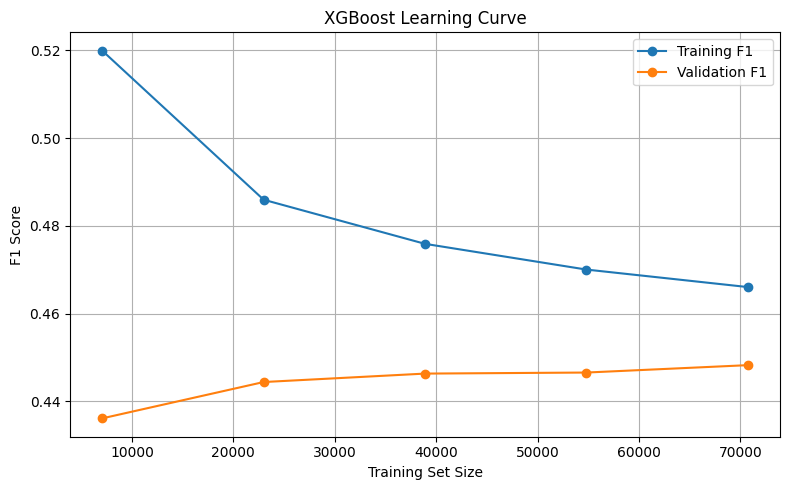

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=xgb_final,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

#Calculate means
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Training F1")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation F1")

plt.xlabel("Training Set Size")
plt.ylabel("F1 Score")
plt.title("XGBoost Learning Curve")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

- The XGBoost learning curve indicated that training F1-score decreased as the training sample increased, while validation F1-score gradually improved and approached a plateau.
- The narrowing gap between the training and validation scores suggests improved generalisation with increasing training data.
- Validation performance stabilised at approximately 0.45 F1-score, indicating that additional training observations may provide limited further improvement under the current modelling configuration.

In [ ]:
cost_df["Predicted_No_Show_Probability"].describe().round(4)

,Predicted_No_Show_Probability
count,22105.0000
mean,0.4465
std,0.2227
min,0.0595
25%,0.1752
50%,0.5200
75%,0.6344
max,0.8272


In [ ]:
cost_df.head(10)

,Age,Gender,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,WaitingDays,AppointmentDayOfWeek,ScheduledHour,Actual_No_Show,Predicted_No_Show,Predicted_No_Show_Probability
0,53,F,0,0,0,0,0,1,18,Monday,10,1,1,0.578638
1,60,F,0,1,1,0,0,1,4,Tuesday,10,0,1,0.546338
2,8,F,0,0,0,0,0,1,20,Wednesday,13,0,1,0.645867
3,64,M,0,0,0,0,0,1,12,Tuesday,7,0,0,0.413309
4,34,F,0,0,0,0,0,0,0,Tuesday,17,0,0,0.099982
5,40,F,0,1,0,0,0,0,0,Monday,7,0,0,0.147821
6,39,M,0,0,0,0,0,0,11,Friday,19,0,1,0.696426
7,0,F,0,0,0,0,0,0,14,Monday,9,1,1,0.713869
8,46,M,0,0,0,0,0,0,0,Wednesday,10,0,0,0.142603
9,10,M,1,0,0,0,0,1,20,Monday,8,0,1,0.629091


#### **Algorithm Bias Analysis**

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

#Create test-results dataframe
bias_df = X_test.copy()

bias_df["Actual_No_Show"] = y_test
bias_df["Predicted_No_Show"] = xgb_test_pred

#Calculate performance by gender
gender_results = []

for gender in bias_df["Gender"].unique():

    group = bias_df[bias_df["Gender"] == gender]

    precision = precision_score(
        group["Actual_No_Show"],
        group["Predicted_No_Show"],
        zero_division=0
    )

    recall = recall_score(
        group["Actual_No_Show"],
        group["Predicted_No_Show"],
        zero_division=0
    )

    f1 = f1_score(
        group["Actual_No_Show"],
        group["Predicted_No_Show"],
        zero_division=0
    )

    gender_results.append({
        "Gender": gender,
        "Appointments": len(group),
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

gender_results_df = pd.DataFrame(gender_results)

#Format metrics
gender_results_df[["Precision", "Recall", "F1_Score"]] = (
    gender_results_df[["Precision", "Recall", "F1_Score"]].round(4)
)

gender_results_df

,Gender,Appointments,Precision,Recall,F1_Score
0,F,14273,0.2998,0.8311,0.4406
1,M,7832,0.3176,0.7926,0.4535


The performance of the selected XGBoost model was compared across gender groups to identify potential differences in predictive performance.

- The model achieved a precision of 29.98%, recall of 83.11% and F1-score of 44.06% for female patients, compared with 31.76%, 79.26% and 45.35%, respectively, for male patients.
- The results indicate relatively small differences in performance across the two groups. Recall was higher for female patients, whereas precision and F1-score were slightly higher for male patients.
- These differences indicate variation in model performance across gender groups but do not, on their own, establish algorithmic bias or discriminatory behaviour.

In [ ]:
#Create age groups
bias_df["Age_Group"] = pd.cut(
    bias_df["Age"],
    bins=[-1, 17, 34, 49, 64, float("inf")],
    labels=["0–17", "18–34", "35–49", "50–64", "65+"]
)

#Calculate performance by age group
age_results = []

for age_group in bias_df["Age_Group"].cat.categories:

    group = bias_df[bias_df["Age_Group"] == age_group]

    precision = precision_score(
        group["Actual_No_Show"],
        group["Predicted_No_Show"],
        zero_division=0
    )

    recall = recall_score(
        group["Actual_No_Show"],
        group["Predicted_No_Show"],
        zero_division=0
    )

    f1 = f1_score(
        group["Actual_No_Show"],
        group["Predicted_No_Show"],
        zero_division=0
    )

    age_results.append({
        "Age_Group": age_group,
        "Appointments": len(group),
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

age_results_df = pd.DataFrame(age_results)

age_results_df[["Precision", "Recall", "F1_Score"]] = (
    age_results_df[["Precision", "Recall", "F1_Score"]].round(4)
)

age_results_df

,Age_Group,Appointments,Precision,Recall,F1_Score
0,0–17,5520,0.3207,0.8601,0.4672
1,18–34,4850,0.3406,0.9285,0.4984
2,35–49,4306,0.3032,0.8947,0.4529
3,50–64,4511,0.2654,0.6365,0.3746
4,65+,2918,0.2389,0.5831,0.3389


Model performance was also assessed across age groups to identify potential differences in predictive performance.

- The model achieved its highest performance among patients aged 18–34, with a precision of 34.06%, recall of 92.85% and F1-score of 49.84%.
- Performance was lower among older patients, with precision, recall and F1-score decreasing to 23.89%, 58.31% and 33.89%, respectively, for patients aged 65 years and older.

The results therefore indicate differences in model performance across age groups, with lower no-show detection performance among older patients. These differences may indicate a potential fairness concern but do not, on their own, establish algorithmic bias or discriminatory behaviour.

In [ ]:
#No-show prevalence by age group
age_prevalence = (
    bias_df.groupby("Age_Group", observed=False)["Actual_No_Show"]
    .agg(
        Appointments="count",
        No_Shows="sum",
        No_Show_Rate="mean"
    )
    .reset_index()
)

age_prevalence["No_Show_Rate"] = (age_prevalence["No_Show_Rate"] * 100).round(2)

age_prevalence

,Age_Group,Appointments,No_Shows,No_Show_Rate
0,0–17,5520,1179,21.36
1,18–34,4850,1147,23.65
2,35–49,4306,902,20.95
3,50–64,4511,784,17.38
4,65+,2918,451,15.46


The age-group analysis showed differences in both observed no-show prevalence and model performance. The highest observed no-show rate occurred among patients aged 18–34 (23.65%), while the lowest occurred among patients aged 65 years and older (15.46%). Model recall followed a similar pattern, decreasing from 92.85% among patients aged 18–34 to 58.31% among patients aged 65 years and older. F1-score also declined from 49.84% to 33.89% across these groups. These results indicate that the model was less effective at identifying no-shows among older patients. The observed differences in no-show prevalence may contribute to differences in model performance; however, they do not fully establish the cause of the observed disparity. The findings therefore indicate a potential fairness concern that should be considered when applying the model across different age groups.

### **Cost-Sensitive Decision Framework**

In [ ]:
#COST-SENSITIVE FRAMEWORK

#Cost of an SMS intervention (Rands)
SMS_COST = 0.25

#Assumed cost associated with a missed appointment (Rands)
MISSED_APPOINTMENT_COST = 700.00

#Assumed relative effectiveness of SMS intervention (from literature review)
#Example: 20% reduction in predicted no-show probability
SMS_EFFECTIVENESS = 0.20

print("SMS cost: R", SMS_COST)
print("Missed appointment cost: R", MISSED_APPOINTMENT_COST)
print("SMS effectiveness:", SMS_EFFECTIVENESS * 100, "%")

SMS cost: R 0.25
Missed appointment cost: R 700.0
SMS effectiveness: 20.0 %


In [ ]:
#Get Predicted no-show probability
p = cost_df["Predicted_No_Show_Probability"]

In [ ]:
#Expected cost if No SMS is sent -- ECno-sms
cost_df["Expected_Cost_No_SMS"] = p * MISSED_APPOINTMENT_COST

In [ ]:
#Calc. probability after SMS intervention
cost_df["Adjusted_No_Show_Probability"] = p * (1 - SMS_EFFECTIVENESS)

In [ ]:
#Expected cost if SMS is sent -- ECsms
cost_df["Expected_Cost_SMS"] = SMS_COST + (cost_df["Adjusted_No_Show_Probability"] * MISSED_APPOINTMENT_COST)

In [ ]:
#Choose the best/lower-cost Intervention action
cost_df["Intervention"] = np.where(cost_df["Expected_Cost_SMS"] < cost_df["Expected_Cost_No_SMS"], "SMS", "No SMS")

In [ ]:
cost_df[["Actual_No_Show", "Predicted_No_Show_Probability", "Expected_Cost_No_SMS", "Adjusted_No_Show_Probability", "Expected_Cost_SMS", "Intervention"]].head(10)

,Actual_No_Show,Predicted_No_Show_Probability,Expected_Cost_No_SMS,Adjusted_No_Show_Probability,Expected_Cost_SMS,Intervention
0,1,0.578638,405.046722,0.462911,324.287384,SMS
1,0,0.546338,382.436279,0.437070,306.199036,SMS
2,0,0.645867,452.107239,0.516694,361.935822,SMS
3,0,0.413309,289.315979,0.330647,231.702789,SMS
4,0,0.099982,69.987335,0.079986,56.239872,SMS
5,0,0.147821,103.474693,0.118257,83.029762,SMS
6,0,0.696426,487.498047,0.557141,390.248444,SMS
7,1,0.713869,499.708496,0.571095,400.016785,SMS
8,0,0.142603,99.822243,0.114083,80.107796,SMS
9,0,0.629091,440.363800,0.503273,352.541077,SMS


In [ ]:
#Calc the economic intervention threshold

intervention_threshold = (SMS_COST / (SMS_EFFECTIVENESS * MISSED_APPOINTMENT_COST))

print(f"Economic intervention threshold: {intervention_threshold:.4f}")
print(f"Percentage: {intervention_threshold * 100:.2f}%")

print(f"\nMinimum model-predicted probability: {cost_df['Predicted_No_Show_Probability'].min():.4f}")
print(f"Maximum model-predicted probability: {cost_df['Predicted_No_Show_Probability'].max():.4f}")

Economic intervention threshold: 0.0018
Percentage: 0.18%

Minimum model-predicted probability: 0.0595
Maximum model-predicted probability: 0.8272


- Under the base cost scenario, comprising an SMS cost of R0.25, a missed-appointment cost of R700 and an assumed SMS effectiveness of 20%, the calculated economic intervention threshold was 0.18%.
- The minimum predicted no-show probability in the test dataset was 5.95%, substantially above the calculated threshold.
- Consequently, all 22,105 test appointments exceeded the economic threshold and were selected for SMS intervention under the base scenario.

In [ ]:
#Summarise the current scenario

total_appointments = len(cost_df)

sms_count = (cost_df["Intervention"] == "SMS").sum()
no_sms_count = (cost_df["Intervention"] == "No SMS").sum()

#Total expected cost if NO appointments receive SMS
total_cost_no_sms = cost_df["Expected_Cost_No_SMS"].sum()

#Total expected cost under the cost-sensitive framework
total_cost_framework = cost_df[["Expected_Cost_SMS", "Expected_Cost_No_SMS"]].min(axis=1).sum()

#Expected saving
expected_saving = total_cost_no_sms - total_cost_framework

print(f"Total appointments: {total_appointments:,}")
print(f"SMS interventions: {sms_count:,}")
print(f"No SMS interventions: {no_sms_count:,}")

print(f"\nExpected cost - No SMS strategy: R{total_cost_no_sms:,.2f}")
print(f"Expected cost - Cost-Sensitive framework: R{total_cost_framework:,.2f}")
print(f"Expected saving vs No SMS: R{expected_saving:,.2f}")

print(f"\nPercentage of appointments receiving SMS: {sms_count / total_appointments * 100:.2f}%")

Total appointments: 22,105
SMS interventions: 22,105
No SMS interventions: 0

Expected cost - No SMS strategy: R6,909,153.50
Expected cost - Cost-Sensitive framework: R5,532,849.00
Expected saving vs No SMS: R1,376,304.50

Percentage of appointments receiving SMS: 100.00%


- Under the base scenario, the cost-sensitive framework recommends SMS intervention for all 22,105 appointments because every model-predicted no-show probability exceeds the 0.18% economic intervention threshold.
- The expected cost under the framework is R5,532,849.00, compared with R6,909,153.50 if no SMS interventions are made, resulting in an expected saving of R1,376,304.50.

In [ ]:
#Average expected cost per appointment

avg_cost_no_sms = total_cost_no_sms / total_appointments
avg_cost_framework = total_cost_framework / total_appointments
avg_saving = expected_saving / total_appointments

print(f"Average expected cost per appointment - No SMS: R{avg_cost_no_sms:.2f}")
print(f"Average expected cost per appointment - Cost-Sensitive Framework: R{avg_cost_framework:.2f}")
print(f"Average expected saving per appointment: R{avg_saving:.2f}")

Average expected cost per appointment - No SMS: R312.56
Average expected cost per appointment - Cost-Sensitive Framework: R250.30
Average expected saving per appointment: R62.26


Under the base scenario, the expected cost per appointment decreases from R312.56 without SMS intervention to R250.30 under the cost-sensitive framework, representing an expected saving of R62.26 per appointment.

In [ ]:
#Sensitivity Analysis

sms_costs = [0.20, 0.25, 0.30, 0.40]
missed_costs = [150, 300, 500, 700, 900, 1000]
effectiveness_values = [0.05, 0.10, 0.20, 0.25]

sensitivity_results = []

total_appointments = len(cost_df)

for sms_cost in sms_costs:
  for missed_cost in missed_costs:
    for effectiveness in effectiveness_values:

        #Economic intervention threshold
        threshold = (sms_cost / (effectiveness * missed_cost))

        #Expected cost: No-SMS
        ec_no_sms = (cost_df["Predicted_No_Show_Probability"] * missed_cost)

        #Probability after SMS
        adjusted_probability = (cost_df["Predicted_No_Show_Probability"] * (1 - effectiveness))

        #Expected cost: SMS
        ec_sms = (sms_cost + (adjusted_probability * missed_cost))

        #Cost-Sensitive intervetion decision
        intervene = ec_sms < ec_no_sms

        #Number of SMS Interventions
        sms_count = intervene.sum()

        #SMS Rate
        sms_rate = round(sms_count / total_appointments * 100, 2)

        #Total expected costs
        total_cost_no_sms = ec_no_sms.sum()
        total_cost_all_sms = ec_sms.sum()

        total_cost_targeted_sms = np.minimum(ec_no_sms, ec_sms).sum()

        #Savings
        saving_vs_no_sms = (total_cost_no_sms - total_cost_targeted_sms)
        saving_vs_all_sms = (total_cost_all_sms - total_cost_targeted_sms)

        #Expected no-shows
        expected_no_shows_no_sms = p.sum()

        expected_no_shows_all_sms = (p * (1 - effectiveness)).sum()

        expected_no_shows_targeted_sms = np.where(intervene, adjusted_probability, p).sum()

        sensitivity_results.append({
            "SMS_Cost": sms_cost,
            "Missed_Appointment_Cost": round(missed_cost, 2),
            "SMS_Effectiveness": effectiveness,
            "Intervention_Threshold": threshold,
            "SMS_Count": sms_count,
            "SMS_Rate": sms_rate,
            "Expected_Cost_No_SMS": round(total_cost_no_sms, 2),
            "Expected_Cost_All_SMS": round(total_cost_all_sms, 2),
            "Expected_Cost_Targeted_SMS": round(total_cost_targeted_sms, 2),
            "Expected_Saving_vs_No_SMS": round(saving_vs_no_sms, 2),
            "Savings_vs_All_SMS": round(saving_vs_all_sms, 2),
            "Expected_No_Shows_No_SMS": round(expected_no_shows_no_sms, 2),
            "Expected_No_Shows_All_SMS": round(expected_no_shows_all_sms, 2),
            "Expected_No_Shows_Targeted_SMS": round(expected_no_shows_targeted_sms, 2)
        })

sensitivity_df = pd.DataFrame(sensitivity_results)
print(f"Total scenarios tested: {len(sensitivity_df)}")

sensitivity_df

Total scenarios tested: 96


,SMS_Cost,Missed_Appointment_Cost,SMS_Effectiveness,Intervention_Threshold,SMS_Count,SMS_Rate,Expected_Cost_No_SMS,Expected_Cost_All_SMS,Expected_Cost_Targeted_SMS,Expected_Saving_vs_No_SMS,Savings_vs_All_SMS,Expected_No_Shows_No_SMS,Expected_No_Shows_All_SMS,Expected_No_Shows_Targeted_SMS
0,0.2,150,0.05,0.026667,22105,100.0,1480532.75,1410927.250,1410927.250,6.960562e+04,0.0,9870.219727,9376.709961,9376.709961
1,0.2,150,0.10,0.013333,22105,100.0,1480532.75,1336900.625,1336900.625,1.436322e+05,0.0,9870.219727,8883.200195,8883.200195
2,0.2,150,0.20,0.006667,22105,100.0,1480532.75,1188847.250,1188847.250,2.916856e+05,0.0,9870.219727,7896.180176,7896.180176
3,0.2,150,0.25,0.005333,22105,100.0,1480532.75,1114820.750,1114820.750,3.657121e+05,0.0,9870.219727,7402.660156,7402.660156
4,0.2,300,0.05,0.013333,22105,100.0,2961065.50,2817433.500,2817433.500,1.436322e+05,0.0,9870.219727,9376.709961,9376.709961
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,0.4,900,0.25,0.001778,22105,100.0,8883197.00,6671239.500,6671239.500,2.211957e+06,0.0,9870.219727,7402.660156,7402.660156
92,0.4,1000,0.05,0.008000,22105,100.0,9870220.00,9385550.000,9385550.000,4.846700e+05,0.0,9870.219727,9376.709961,9376.709961
93,0.4,1000,0.10,0.004000,22105,100.0,9870220.00,8892040.000,8892040.000,9.781800e+05,0.0,9870.219727,8883.200195,8883.200195
94,0.4,1000,0.20,0.002000,22105,100.0,9870220.00,7905018.000,7905018.000,1.965202e+06,0.0,9870.219727,7896.180176,7896.180176


In [ ]:
sensitivity_df["SMS_Rate"].value_counts().sort_index()

,count
SMS_Rate,
100.0,96


In [ ]:
#Inspect scenarios where SMS_Rate is below 100%
targeted_sms_scenarios = sensitivity_df[(sensitivity_df["SMS_Rate"] > 0) & (sensitivity_df["SMS_Rate"] <100)].sort_values(by='Savings_vs_All_SMS', ascending=False)

targeted_sms_scenarios

,SMS_Cost,Missed_Appointment_Cost,SMS_Effectiveness,Intervention_Threshold,SMS_Count,SMS_Rate,Expected_Cost_No_SMS,Expected_Cost_All_SMS,Expected_Cost_Targeted_SMS,Expected_Saving_vs_No_SMS,Savings_vs_All_SMS,Expected_No_Shows_No_SMS,Expected_No_Shows_All_SMS,Expected_No_Shows_Targeted_SMS


Across the 96 scenarios based on the selected ranges, the framework recommended SMS for all appointments. Additional boundary analysis was therefore conducted to identify the combinations of intervention cost, missed-appointment cost and effectiveness under which selective intervention would occur.

In [ ]:
#Compare the economic threshold with the model probabilities
threshold = 2.00 / (0.05 * 150)

print(f"Economic threshold: {threshold:.4f}")
print(f"Economic threshold: {threshold * 100:.2f}%")

print(f"Minimum predicted probability: {cost_df['Predicted_No_Show_Probability'].min():.4f}")
print(f"Number below threshold: {(cost_df['Predicted_No_Show_Probability'] < threshold).sum()}")
print(f"Number above/equal threshold: {(cost_df['Predicted_No_Show_Probability'] >= threshold).sum()}")

Economic threshold: 0.2667
Economic threshold: 26.67%
Minimum predicted probability: 0.0595
Number below threshold: 6950
Number above/equal threshold: 15155


In [ ]:
#Identify scenarios where the framework is selective

#Total scenarios where SMS rate is below 100%
print(f"Targeted SMS scenarios: {len(targeted_sms_scenarios)}")

#Total scenarios where SMS rate is 100%
print(f"Universal SMS scenarios: {(sensitivity_df['SMS_Rate'] == 100).sum()}")

#Total scenarios where SMS rate is 0%
print(f"No SMS scenarios: {(sensitivity_df['SMS_Rate'] == 0).sum()}")

Targeted SMS scenarios: 0
Universal SMS scenarios: 96
No SMS scenarios: 0


In [ ]:
#Base scenario vs Selective scenario

#Base scenario values already calculated earlier
base_sms_cost = 0.25
base_missed_cost = 700.00
base_effectiveness = 0.20

base_threshold = (base_sms_cost / (base_effectiveness * base_missed_cost))

base_p = cost_df["Predicted_No_Show_Probability"]

base_ec_no_sms = base_p * base_missed_cost
base_prob_after_sms = base_p * (1 - base_effectiveness)
base_ec_sms = base_sms_cost + (base_prob_after_sms * base_missed_cost)

base_intervene = base_ec_sms < base_ec_no_sms

base_sms_count = base_intervene.sum()

base_expected_no_shows = np.where(base_intervene, base_prob_after_sms, base_p).sum()

base_cost_no_sms = base_ec_no_sms.sum()
base_cost_universal = base_ec_sms.sum()
base_cost_sensitive = np.minimum(base_ec_no_sms, base_ec_sms).sum()

base_saving_no_sms = (base_cost_no_sms - base_cost_sensitive)

base_saving_universal = (base_cost_universal - base_cost_sensitive)

#Selective scenario
sel_sms_cost = 2
sel_missed_cost = 150.00
sel_effectiveness = 0.05

sel_threshold = (sel_sms_cost / (sel_effectiveness * sel_missed_cost))

sel_ec_no_sms = (base_p * sel_missed_cost)
sel_prob_after_sms = (base_p * (1 - sel_effectiveness))
sel_ec_sms = (sel_sms_cost + sel_prob_after_sms * sel_missed_cost)
sel_intervene = sel_ec_sms < sel_ec_no_sms

sel_sms_count = sel_intervene.sum()

sel_expected_no_shows = np.where(sel_intervene, sel_prob_after_sms, base_p).sum()
sel_cost_no_sms = sel_ec_no_sms.sum()
sel_cost_universal = sel_ec_sms.sum()
sel_cost_sensitive = np.minimum(sel_ec_no_sms, sel_ec_sms).sum()

sel_saving_no_sms = (sel_cost_no_sms - sel_cost_sensitive)
sel_saving_universal = (sel_cost_universal - sel_cost_sensitive)

#Building the summary table
summary_df = pd.DataFrame({
    "Measure": [
        "SMS cost",
        "Missed appointment cost",
        "SMS effectiveness",
        "Economic intervention threshold",
        "SMS interventions",
        "SMS reduction",
        "Expected no-shows - No SMS",
        "Expected no-shows - Framework",
        "Expected cost - No SMS",
        "Expected cost - Universal SMS",
        "Expected cost - Framework",
        "Saving vs No SMS",
        "Saving vs Universal SMS"
    ],

    "Base Scenario": [
        base_sms_cost,
        base_missed_cost,
        base_effectiveness,
        base_threshold,
        base_sms_count,
        0,
        base_p.sum(),
        base_expected_no_shows,
        base_cost_no_sms,
        base_cost_universal,
        base_cost_sensitive,
        base_saving_no_sms,
        base_saving_universal
    ],

    "Illustrative Selective Scenario": [
        sel_sms_cost,
        sel_missed_cost,
        sel_effectiveness,
        sel_threshold,
        sel_sms_count,
        total_appointments - sel_sms_count,
        base_p.sum(),
        sel_expected_no_shows,
        sel_cost_no_sms,
        sel_cost_universal,
        sel_cost_sensitive,
        sel_saving_no_sms,
        sel_saving_universal
    ]
})

In [ ]:
summary_df

,Measure,Base Scenario,Illustrative Selective Scenario
0,SMS cost,2.500000e-01,2.000000e+00
1,Missed appointment cost,7.000000e+02,1.500000e+02
2,SMS effectiveness,2.000000e-01,5.000000e-02
3,Economic intervention threshold,1.785714e-03,2.666667e-01
4,SMS interventions,2.210500e+04,1.515500e+04
5,SMS reduction,0.000000e+00,6.950000e+03
6,Expected no-shows - No SMS,9.870220e+03,9.870220e+03
7,Expected no-shows - Framework,7.896176e+03,9.427091e+03
8,Expected cost - No SMS,6.909154e+06,1.480533e+06
9,Expected cost - Universal SMS,5.532849e+06,1.450716e+06


In [ ]:
#Format summary table for reporting
summary_display = summary_df.copy()

#Format currency rows
currency_rows = [
    "SMS cost",
    "Missed appointment cost",
    "Expected no-shows - No SMS",
    "Expected cost - Universal SMS",
    "Expected no-shows - Framework",
    "Expected cost - No SMS",
    "Expected cost - Framework",
    "Saving vs Universal SMS",
    "Saving vs No SMS"
]

for row in currency_rows:
    summary_display.loc[
        summary_display["Measure"] == row,
        ["Base Scenario", "Illustrative Selective Scenario"]
    ] = summary_display.loc[
        summary_display["Measure"] == row,
        ["Base Scenario", "Illustrative Selective Scenario"]
    ].map(lambda x: f"R{x:,.2f}")

#Format percentage rows
percentage_rows = ["SMS effectiveness", "Economic intervention threshold"]

for row in percentage_rows:
    summary_display.loc[
        summary_display["Measure"] == row,
        ["Base Scenario", "Illustrative Selective Scenario"]
    ] = summary_display.loc[
        summary_display["Measure"] == row,
        ["Base Scenario", "Illustrative Selective Scenario"]
    ].map(lambda x: f"{x * 100:.2f}%")

#Format appointment counts
count_rows = ["SMS interventions", "SMS reduction"]

for row in count_rows:
    summary_display.loc[
        summary_display["Measure"] == row,
        ["Base Scenario", "Illustrative Selective Scenario"]
    ] = summary_display.loc[
        summary_display["Measure"] == row,
        ["Base Scenario", "Illustrative Selective Scenario"]
    ].map(lambda x: f"{int(x):,.2f}")

#Display
summary_display

/tmp/ipykernel_2246/2169521206.py:18: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['R0.25']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[
/tmp/ipykernel_2246/2169521206.py:18: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['R2.00']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[


,Measure,Base Scenario,Illustrative Selective Scenario
0,SMS cost,R0.25,R2.00
1,Missed appointment cost,R700.00,R150.00
2,SMS effectiveness,20.00%,5.00%
3,Economic intervention threshold,0.18%,26.67%
4,SMS interventions,"22,105.00","15,155.00"
5,SMS reduction,0.00,"6,950.00"
6,Expected no-shows - No SMS,"R9,870.22","R9,870.22"
7,Expected no-shows - Framework,"R7,896.18","R9,427.09"
8,Expected cost - No SMS,"R6,909,153.50","R1,480,532.88"
9,Expected cost - Universal SMS,"R5,532,849.00","R1,450,716.25"


**Notes**:
- The R2.00 SMS cost used in the Illustrative Selective Scenario represents an illustrative stress-test assumption rather than a typical South African bulk-SMS cost.
- The scenario was included to examine how the cost-sensitive framework behaves when the intervention cost is relatively high and therefore produces a more selective intervention strategy.
- The Illustrative Selective Scenario was intentionally constructed as a stress-test scenario using a relatively high SMS cost of R2.00, a missed-appointment cost of R150.00 and an SMS effectiveness of 5%.
- The R2.00 SMS cost should not be interpreted as the expected or typical cost of SMS intervention in the South African context.
- Rather, the assumption provides a higher-cost boundary condition for examining whether the framework can transition from universal to selective intervention.
- Under these assumptions, the economic intervention threshold increased to 26.67%, resulting in SMS recommendations for 15,155 of the 22,105 test appointments (68.56%).
- This represents a reduction of 6,950 SMS interventions (31.44%) compared with universal SMS, while producing an expected saving of R6,342.50 compared with sending SMS to all appointments.